In [13]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [14]:
# Load CSV
try:
    df = pd.read_csv("../Datasets/csv/jamming-merged-gps-only.csv")
except FileNotFoundError:
    print("Error: The file '../Datasets/csv/jamming-merged-gps-only.csv' was not found.")
    print("Please make sure the path is correct.")
    exit()

In [15]:
print(df.head())
print(df.info())

   timestamp      q[0]      q[1]      q[2]      q[3]  delta_q_reset[0]  \
0  332828103 -0.278094 -0.004139 -0.002317  0.960542          0.999999   
1  333003247 -0.278094 -0.004139 -0.002317  0.960542          0.999999   
2  333008246 -0.278094 -0.004139 -0.002317  0.960542          0.999999   
3  333013247 -0.278096 -0.004139 -0.002316  0.960542          0.999999   
4  333022041 -0.278098 -0.004136 -0.002315  0.960541          0.999999   

   delta_q_reset[1]  delta_q_reset[2]  delta_q_reset[3]  quat_reset_counter  \
0      5.520000e-10     -4.980000e-10          0.001079                   3   
1      5.520000e-10     -4.980000e-10          0.001079                   3   
2      5.520000e-10     -4.980000e-10          0.001079                   3   
3      5.520000e-10     -4.980000e-10          0.001079                   3   
4      5.520000e-10     -4.980000e-10          0.001079                   3   

   ...  v_z_valid  xy_reset_counter  z_reset_counter  vxy_reset_counter  \
0  ..

In [16]:
features = [
    'timestamp', 'q[0]', 'q[1]', 'q[2]', 'q[3]', 'delta_q_reset[0]',
    'delta_q_reset[1]', 'delta_q_reset[2]', 'delta_q_reset[3]',
    'quat_reset_counter', 'lat_x', 'lon_x', 'alt_x', 'alt_ellipsoid_x',
    'delta_alt', 'eph_x', 'epv_x', 'terrain_alt', 'lat_lon_reset_counter',
    'alt_reset_counter', 'terrain_alt_valid', 'dead_reckoning',
    'time_utc_usec', 'lat_y', 'lon_y', 'alt_y', 'alt_ellipsoid_y',
    's_variance_m_s', 'c_variance_rad', 'eph_y', 'epv_y', 'hdop', 'vdop',
    'noise_per_ms', 'jamming_indicator', 'vel_m_s', 'vel_n_m_s',
    'vel_e_m_s', 'vel_d_m_s', 'cog_rad', 'timestamp_time_relative',
    'heading_offset', 'fix_type', 'vel_ned_valid', 'satellites_used',
    'ref_lat', 'ref_lon', 'x', 'y', 'z', 'delta_xy[0]', 'delta_xy[1]',
    'delta_z', 'vx', 'vy', 'vz', 'z_deriv', 'delta_vxy[0]', 'delta_vxy[1]',
    'delta_vz', 'ax', 'ay', 'az', 'heading_y', 'delta_heading', 'ref_alt',
    'dist_bottom', 'eph', 'epv', 'evh', 'evv', 'xy_valid', 'z_valid',
    'v_xy_valid', 'v_z_valid', 'xy_reset_counter', 'z_reset_counter',
    'vxy_reset_counter', 'vz_reset_counter', 'heading_reset_counter',
    'xy_global', 'z_global', 'dist_bottom_valid', 'label'
]

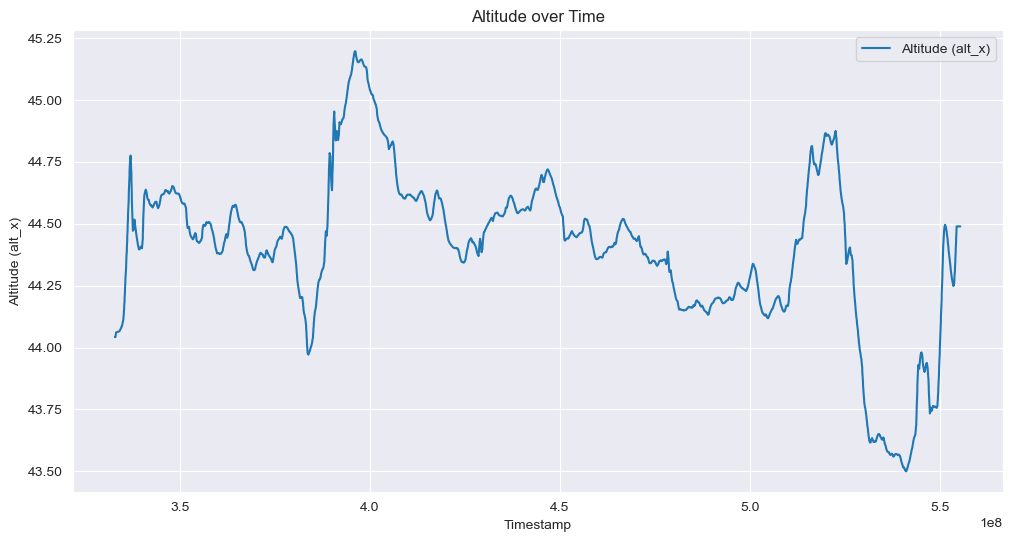

In [17]:
plt.figure(figsize=(12, 6))
plt.plot(df['timestamp'], df['alt_x'], label='Altitude (alt_x)')
plt.xlabel('Timestamp')
plt.ylabel('Altitude (alt_x)')
plt.title('Altitude over Time')
plt.legend()
plt.grid(True)
plt.show()


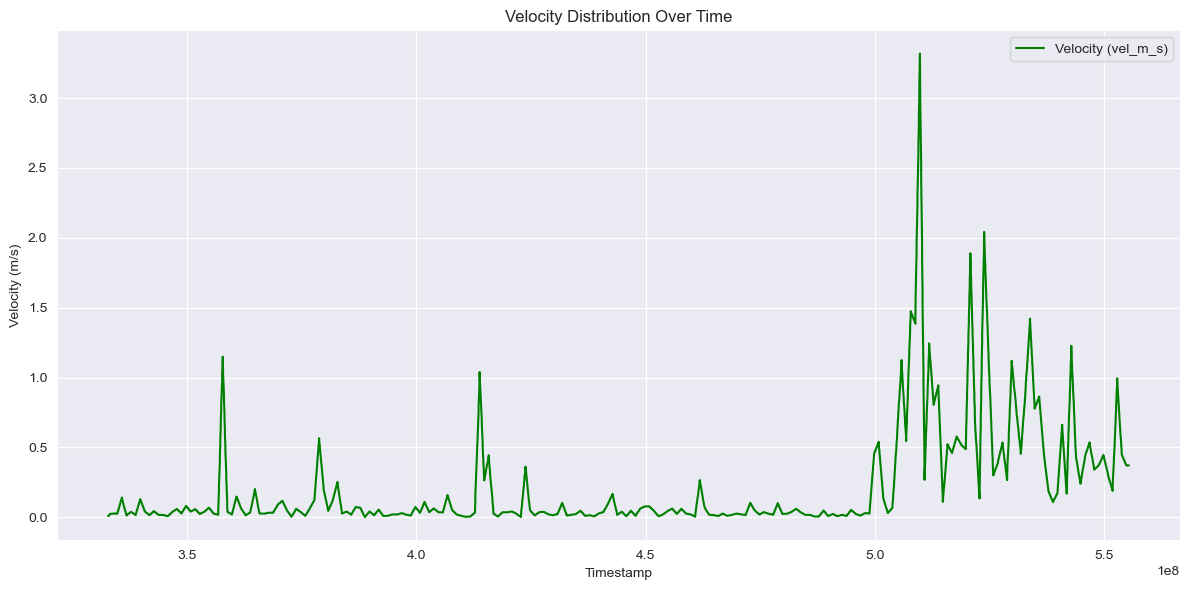

In [18]:
plt.figure(figsize=(12, 6))
plt.plot(df['timestamp'], df['vel_m_s'], label='Velocity (vel_m_s)', color='green')
plt.xlabel('Timestamp')
plt.ylabel('Velocity (m/s)')
plt.title('Velocity Distribution Over Time')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

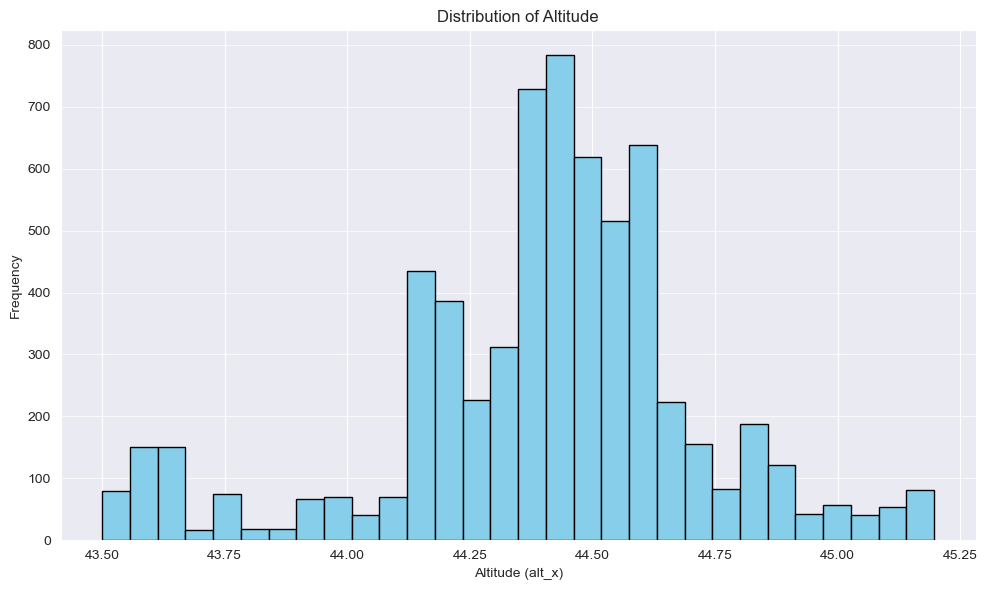

In [19]:
plt.figure(figsize=(10, 6))
plt.hist(df['alt_x'], bins=30, color='skyblue', edgecolor='black')
plt.xlabel('Altitude (alt_x)')
plt.ylabel('Frequency')
plt.title('Distribution of Altitude')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()


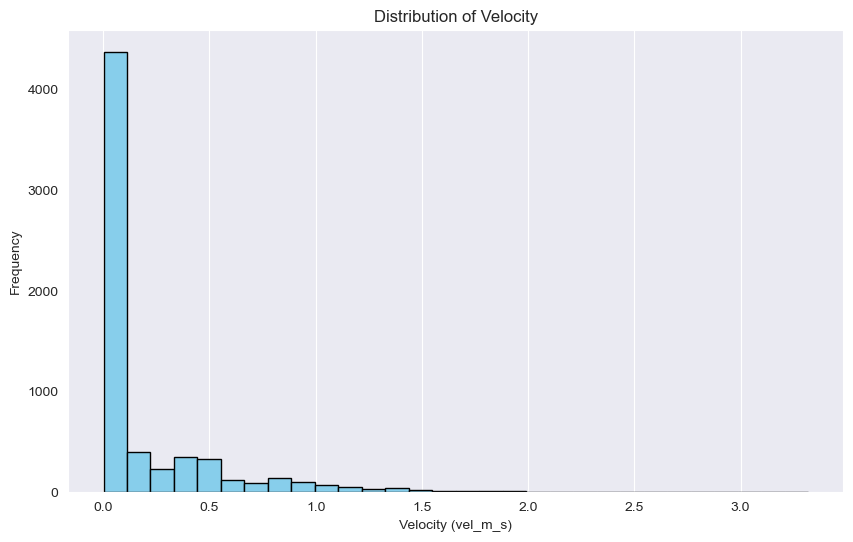

In [20]:
plt.figure(figsize=(10, 6))
plt.hist(df['vel_m_s'], bins=30, color='skyblue', edgecolor='black')
plt.xlabel('Velocity (vel_m_s)')
plt.ylabel('Frequency')
plt.title('Distribution of Velocity')
plt.grid(axis='y')
plt.show()

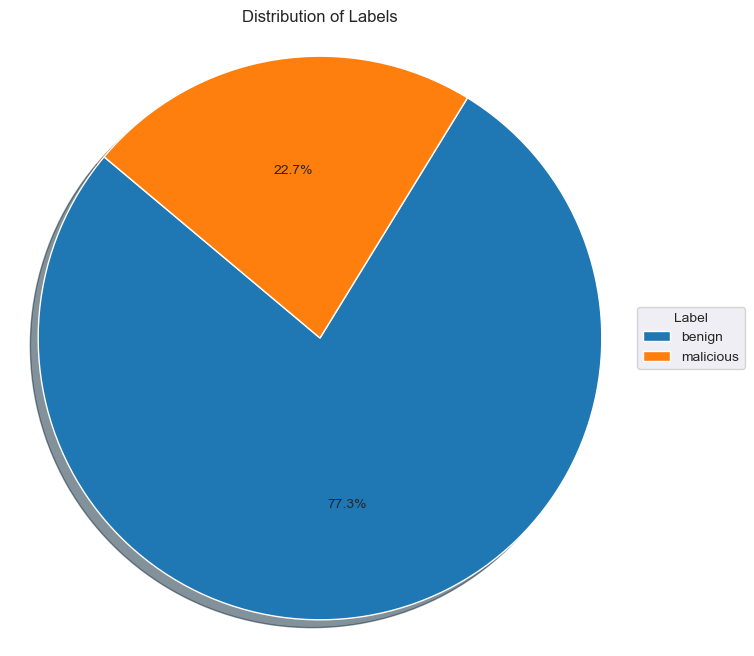

In [21]:
if 'label' in df.columns:
    label_counts = df['label'].value_counts()

    plt.figure(figsize=(8, 8))
    wedges, texts, autotexts = plt.pie(
        label_counts,
        labels=None,
        autopct='%1.1f%%',
        startangle=140,
        shadow=True
    )
    plt.title('Distribution of Labels')
    plt.axis('equal')
    plt.legend(wedges, label_counts.index, title="Label", bbox_to_anchor=(1, 0.5), loc="center left")
    plt.show()
else:
    print("The 'label' column was not found in your DataFrame.")

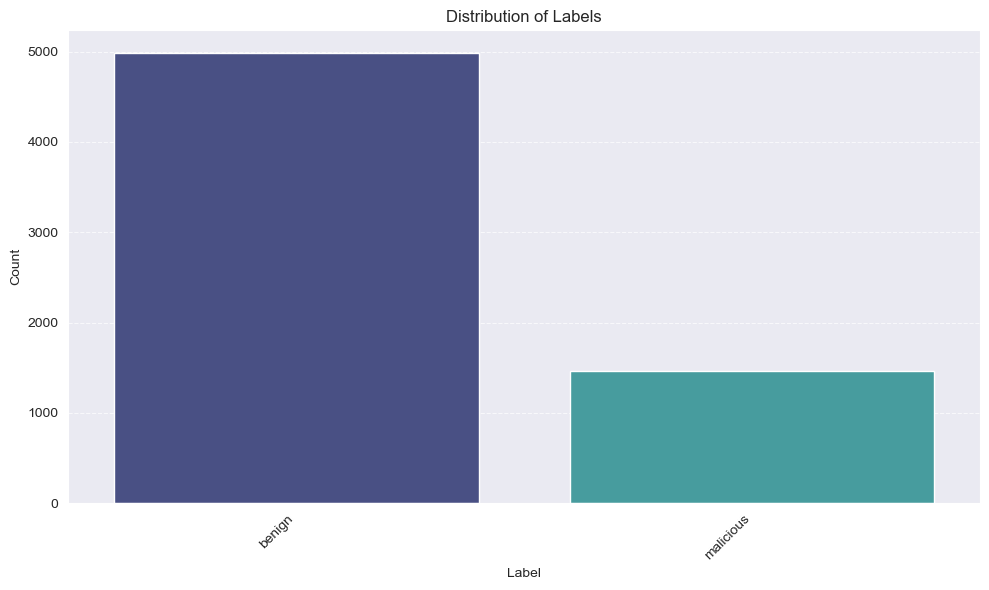

In [22]:
if 'label' in df.columns:
    plt.figure(figsize=(10, 6))

    sns.countplot(x='label', data=df, hue='label', palette='mako', legend=False)

    plt.title('Distribution of Labels')
    plt.xlabel('Label')
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
else:
    print("The 'label' column was not found in your DataFrame.")

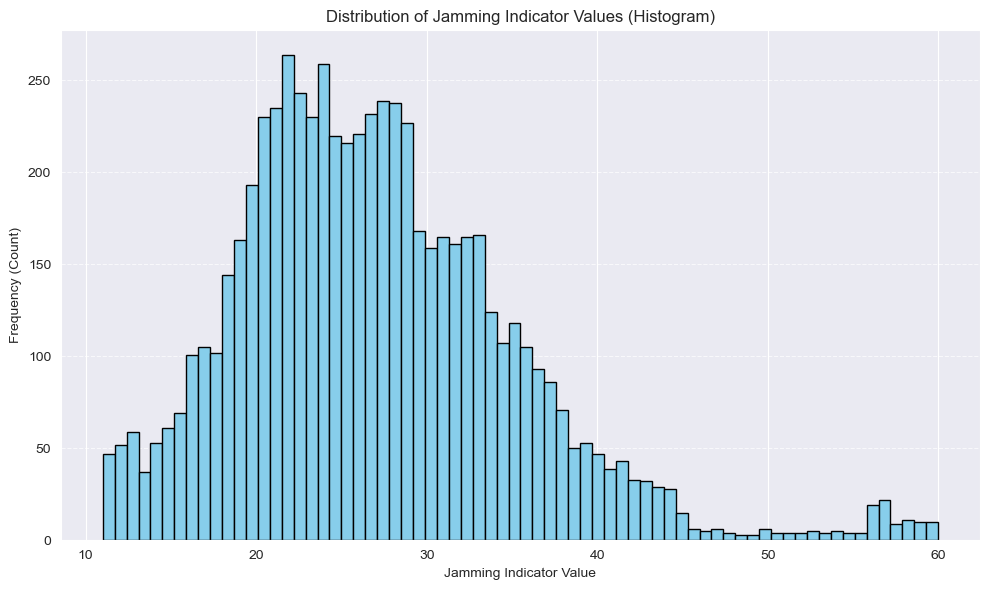

In [23]:
if 'jamming_indicator' in df.columns:
    plt.figure(figsize=(10, 6))

    plt.hist(df['jamming_indicator'].dropna(), bins=70, color='skyblue', edgecolor='black')

    plt.title('Distribution of Jamming Indicator Values (Histogram)')
    plt.xlabel('Jamming Indicator Value')
    plt.ylabel('Frequency (Count)')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
else:
    print("The 'jamming_indicator' column was not found in your DataFrame.")

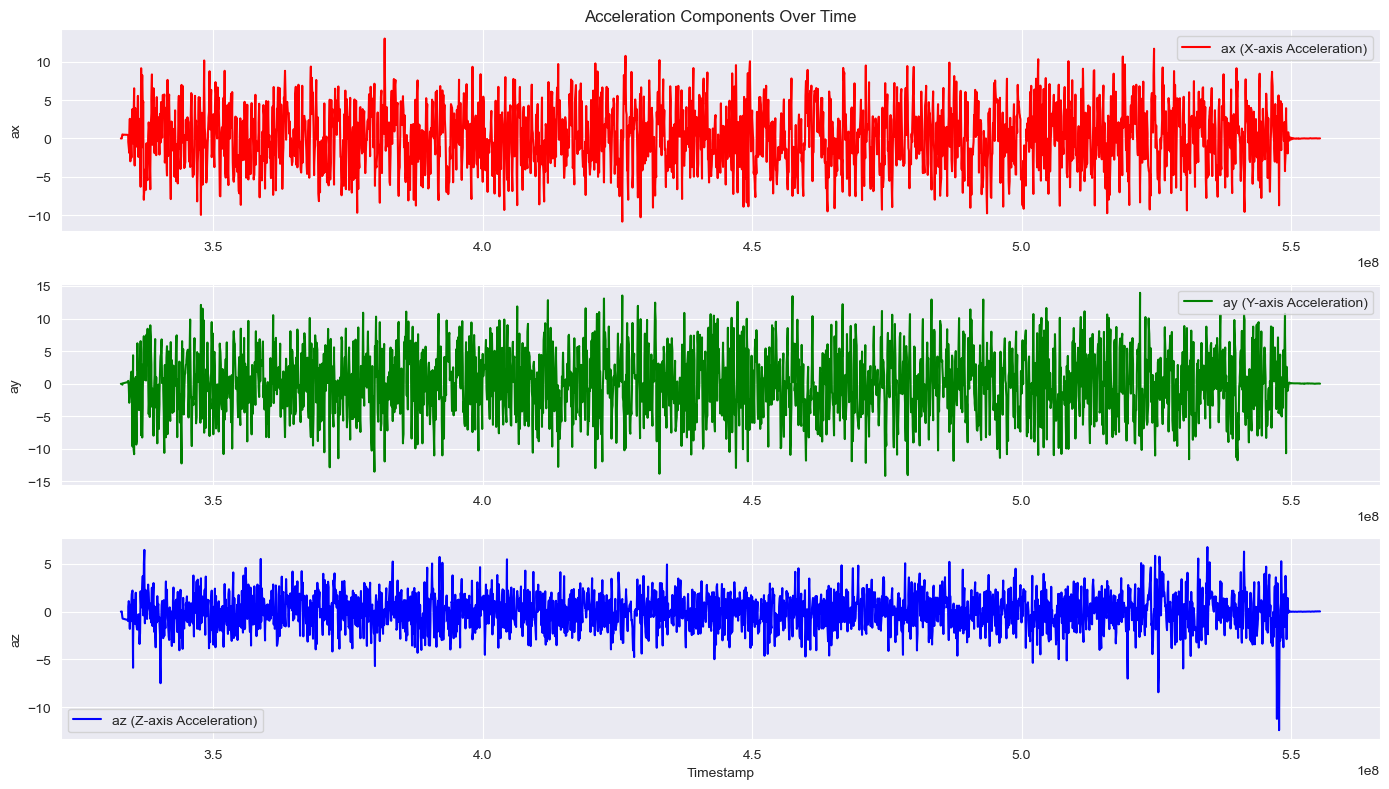

In [24]:
accel_columns_present = all(col in df.columns for col in ['ax', 'ay', 'az', 'timestamp'])
if accel_columns_present:
    plt.figure(figsize=(14, 8))

    plt.subplot(3, 1, 1)
    plt.plot(df['timestamp'], df['ax'], label='ax (X-axis Acceleration)', color='red')
    plt.ylabel('ax')
    plt.title('Acceleration Components Over Time')
    plt.legend()
    plt.grid(True)

    plt.subplot(3, 1, 2)
    plt.plot(df['timestamp'], df['ay'], label='ay (Y-axis Acceleration)', color='green')
    plt.ylabel('ay')
    plt.legend()
    plt.grid(True)

    plt.subplot(3, 1, 3)
    plt.plot(df['timestamp'], df['az'], label='az (Z-axis Acceleration)', color='blue')
    plt.xlabel('Timestamp')
    plt.ylabel('az')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()
else:
    print("Could not plot acceleration data. Check if 'ax', 'ay', 'az', and 'timestamp' columns exist.")